# 03b Сравнение SurvivalAft и Discrete-Time Survival на validation

## 1. Импорты и каталоги

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, logistic, gumbel_l
from catboost import CatBoostRegressor, CatBoostClassifier
from sksurv.util import Surv
from sksurv.metrics import brier_score, concordance_index_censored
from sksurv.nonparametric import kaplan_meier_estimator

ROOT = Path(r"C:\Users\Ева\Desktop\Хакатон Альфа\AURELIUS\scoring")
DATA_PATH = ROOT / "data/processed/ml_survival_dataset.parquet"
AFT_DIR = ROOT / "models/experiments/survival_v3_baseline"
DT_DIR = ROOT / "models/experiments/survival_v3_discrete_time"
OUT_DIR = ROOT / "models/experiments/survival_v3_comparison"
OUT_DIR.mkdir(parents=True, exist_ok=True)

for p in [DATA_PATH, AFT_DIR / "model.cbm", AFT_DIR / "features.json", AFT_DIR / "splits.npz", DT_DIR / "model.cbm", DT_DIR / "features.json"]:
    if not p.exists():
        raise FileNotFoundError(f"Отсутствует файл: {p}")
print("Результаты будут сохранены:", OUT_DIR)

Результаты будут сохранены: C:\Users\Ева\Desktop\Хакатон Альфа\AURELIUS\scoring\models\experiments\survival_v3_comparison


## 2. Загружаем **одинаковые** validation-эпизоды и обе модели

In [2]:
df = pd.read_parquet(DATA_PATH)
with np.load(AFT_DIR / "splits.npz") as s:
    train_idx = s["train_idx"].copy()
    val_idx = s["val_idx"].copy()
    test_idx = s["test_idx"].copy()  # не используем

df_train = df.iloc[train_idx].copy()
df_val = df.iloc[val_idx].copy()
train_36 = df_train.loc[df_train["term_months"] == 36].copy().reset_index(drop=True)
val_36 = df_val.loc[df_val["term_months"] == 36].copy().reset_index(drop=True)

with open(AFT_DIR / "features.json", encoding="utf-8") as f:
    aft_cfg = json.load(f)
with open(DT_DIR / "features.json", encoding="utf-8") as f:
    dt_cfg = json.load(f)

AFT_FEATURES = aft_cfg["features"]
AFT_CATS = aft_cfg["categorical_features"]
DT_FEATURES = dt_cfg["features"]
DT_CATS = dt_cfg["categorical_features"]
assert "month_on_book" in DT_FEATURES
assert "term_months" not in DT_FEATURES
assert len(val_36) > 0 and len(train_36) > 0
assert val_36["episode_id"].is_unique

aft = CatBoostRegressor()
aft.load_model(str(AFT_DIR / "model.cbm"))
dt = CatBoostClassifier()
dt.load_model(str(DT_DIR / "model.cbm"))
print("Train 36m:", len(train_36), "| Validation 36m:", len(val_36))
print("AFT features:", len(AFT_FEATURES), "| DT features:", len(DT_FEATURES))

Train 36m: 33772 | Validation 36m: 7185
AFT features: 15 | DT features: 15


## 3. Прогнозы SurvivalAft: PD12, PD24 и PD36

In [3]:
aft_params = aft.get_all_params()
loss = aft_params["loss_function"]
if not loss.startswith("SurvivalAft"):
    raise ValueError(f"Ожидалась SurvivalAft, получено: {loss}")

# Например: SurvivalAft:dist=Normal;scale=1.0
opts = dict(piece.split("=", 1) for piece in loss.split(":", 1)[1].split(";") if "=" in piece)
dist = opts.get("dist", "Normal")
scale = float(opts.get("scale", 1.0))
if scale <= 0:
    raise ValueError("scale должен быть > 0")

X_aft = val_36[AFT_FEATURES].copy()
for col in AFT_CATS:
    X_aft[col] = X_aft[col].fillna("UNKNOWN").astype(str)
mu = np.asarray(aft.predict(X_aft), dtype=float).reshape(-1)

months = np.array([12., 24., 36.])
z = (np.log(months)[None, :] - mu[:, None]) / scale
if dist == "Normal":
    aft_pd = norm.cdf(z)
elif dist == "Logistic":
    aft_pd = logistic.cdf(z)
elif dist == "Extreme":
    aft_pd = gumbel_l.cdf(z)
else:
    raise ValueError(f"Неизвестное распределение SurvivalAft: {dist}")

assert aft_pd.shape == (len(val_36), 3)
print("AFT:", loss)
print("PD36: min / median / max:", *(f"{v:.2%}" for v in [aft_pd[:, 2].min(), np.median(aft_pd[:, 2]), aft_pd[:, 2].max()]))

AFT: SurvivalAft:dist=Normal;scale=1.0
PD36: min / median / max: 47.55% 53.71% 95.71%


## 4. Прогнозы Discrete-Time: PD12, PD24 и PD36

In [4]:
def predict_dt_pd36(model, apps, feature_names, categorical_names, batch_size=1500):
    base_features = [f for f in feature_names if f != "month_on_book"]
    outputs = []
    for start in range(0, len(apps), batch_size):
        chunk = apps.iloc[start:start + batch_size].reset_index(drop=True)
        n = len(chunk)
        repeated = np.repeat(np.arange(n), 36)
        X = chunk.iloc[repeated][base_features].reset_index(drop=True)
        X["month_on_book"] = np.tile(np.arange(1, 37, dtype=np.int16), n)
        for col in categorical_names:
            X[col] = X[col].fillna("UNKNOWN").astype(str)
        h = np.asarray(model.predict_proba(X[feature_names])[:, 1]).reshape(n, 36)
        h = np.clip(h, 0.0, 1.0)
        pd_curve = -np.expm1(np.cumsum(np.log1p(-h), axis=1))
        outputs.append(pd_curve[:, [11, 23, 35]])
    return np.vstack(outputs)

dt_pd = predict_dt_pd36(dt, val_36, DT_FEATURES, DT_CATS)
assert dt_pd.shape == aft_pd.shape
assert np.all(np.diff(dt_pd, axis=1) >= -1e-12)
print("DT PD36: min / median / max:", *(f"{v:.2%}" for v in [dt_pd[:, 2].min(), np.median(dt_pd[:, 2]), dt_pd[:, 2].max()]))

DT PD36: min / median / max: 18.06% 34.07% 100.00%


## 5. Одинаковая survival-оценка для обеих моделей

In [5]:
y_train_36 = Surv.from_arrays(
    event=train_36["event"].to_numpy(dtype=bool),
    time=train_36["duration"].to_numpy(dtype=float),
)
y_val_36 = Surv.from_arrays(
    event=val_36["event"].to_numpy(dtype=bool),
    time=val_36["duration"].to_numpy(dtype=float),
)
EVAL_TIMES = np.array([12., 24.])

comparison_rows = []
for name, pd_matrix in [("SurvivalAft", aft_pd), ("Discrete-Time", dt_pd)]:
    survival = 1.0 - pd_matrix[:, :2]
    _, bs = brier_score(y_train_36, y_val_36, survival, EVAL_TIMES)
    cidx = concordance_index_censored(
        val_36["event"].to_numpy(dtype=bool),
        val_36["duration"].to_numpy(dtype=float),
        pd_matrix[:, 2],
    )[0]
    comparison_rows.append({
        "model": name,
        "n_val_36": len(val_36),
        "c_index_36m": float(cidx),
        "ipcw_brier_12m": float(bs[0]),
        "ipcw_brier_24m": float(bs[1]),
        "mean_brier_12_24": float(np.mean(bs)),
        "pd36_min": float(pd_matrix[:, 2].min()),
        "pd36_p05": float(np.quantile(pd_matrix[:, 2], .05)),
        "pd36_median": float(np.median(pd_matrix[:, 2])),
        "pd36_p95": float(np.quantile(pd_matrix[:, 2], .95)),
        "pd36_max": float(pd_matrix[:, 2].max()),
    })

comparison = pd.DataFrame(comparison_rows)
display(comparison.round(5))
comparison.to_csv(OUT_DIR / "comparison_metrics.csv", index=False)

,model,n_val_36,c_index_36m,ipcw_brier_12m,ipcw_brier_24m,mean_brier_12_24,pd36_min,pd36_p05,pd36_median,pd36_p95,pd36_max
0,SurvivalAft,7185,0.63528,0.12742,0.20561,0.16652,0.47552,0.49257,0.53714,0.83362,0.95713
1,Discrete-Time,7185,0.64498,0.12446,0.18344,0.15395,0.18057,0.23719,0.34071,0.78777,1.00000


## 6. Калибровка PD12 на **одном** графике

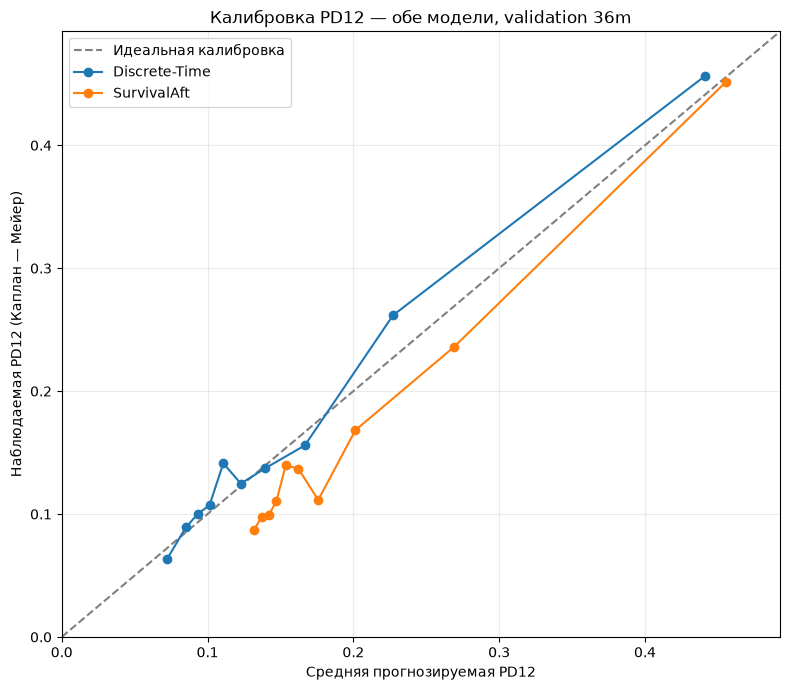

,model,weighted_abs_calibration_error,weighted_bias_observed_minus_predicted
0,Discrete-Time,0.01207,0.00768
1,SurvivalAft,0.03382,-0.03382


Примечание: ошибка калибровки здесь — агрегат по децилям, не ICI на индивидуальных прогнозах.


In [6]:
def calibration_table(apps, predicted_pd12, model_name, horizon=12.0):
    work = apps[["duration", "event"]].copy().reset_index(drop=True)
    work["pd12"] = predicted_pd12
    work["decile"] = pd.qcut(work["pd12"], q=10, labels=False, duplicates="drop")
    rows = []
    for decile, group in work.groupby("decile", observed=True):
        km_t, km_s = kaplan_meier_estimator(
            group["event"].to_numpy(dtype=bool),
            group["duration"].to_numpy(dtype=float),
        )
        pos = np.searchsorted(km_t, horizon, side="right") - 1
        observed_pd = float(1.0 - km_s[pos]) if pos >= 0 else 0.0
        rows.append({
            "model": model_name,
            "decile": int(decile),
            "n": len(group),
            "predicted_pd12": float(group["pd12"].mean()),
            "observed_pd12_km": observed_pd,
            "calibration_error": observed_pd - float(group["pd12"].mean()),
        })
    return pd.DataFrame(rows)

calibration = pd.concat([
    calibration_table(val_36, aft_pd[:, 0], "SurvivalAft"),
    calibration_table(val_36, dt_pd[:, 0], "Discrete-Time"),
], ignore_index=True)
calibration.to_csv(OUT_DIR / "calibration_12m.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 7))
limit = max(0.05, float(calibration[["predicted_pd12", "observed_pd12_km"]].max().max()) * 1.08)
ax.plot([0, limit], [0, limit], "--", color="gray", label="Идеальная калибровка")
for name, grp in calibration.groupby("model"):
    grp = grp.sort_values("predicted_pd12")
    ax.plot(grp["predicted_pd12"], grp["observed_pd12_km"], "o-", label=name)
ax.set(xlim=(0, limit), ylim=(0, limit), xlabel="Средняя прогнозируемая PD12", ylabel="Наблюдаемая PD12 (Каплан — Мейер)", title="Калибровка PD12 — обе модели, validation 36m")
ax.grid(alpha=.25)
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "calibration_comparison_12m.png", dpi=170, bbox_inches="tight")
plt.show()

calibration_summary = (calibration.assign(abs_error=lambda x: x.calibration_error.abs())
                       .groupby("model").apply(lambda g: pd.Series({
                           "weighted_abs_calibration_error": np.average(g["abs_error"], weights=g["n"]),
                           "weighted_bias_observed_minus_predicted": np.average(g["calibration_error"], weights=g["n"]),
                       }), include_groups=False).reset_index())
display(calibration_summary.round(5))
calibration_summary.to_csv(OUT_DIR / "calibration_summary.csv", index=False)
print("Примечание: ошибка калибровки здесь — агрегат по децилям, не ICI на индивидуальных прогнозах.")

## 7. Распределение PD36

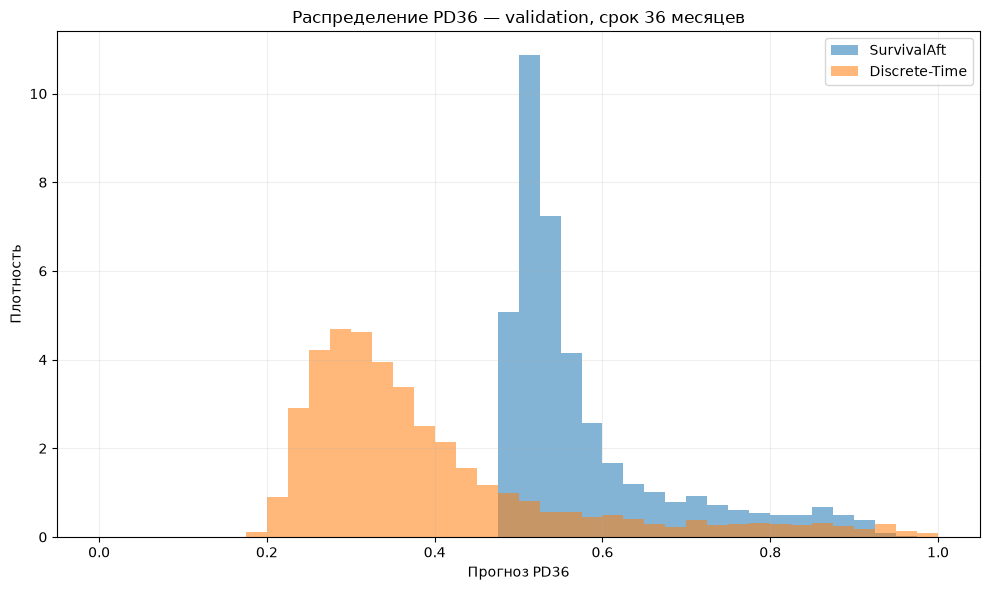

SurvivalAft: PD36 > 90%: 1.22%; PD36 < 20%: 0.00%
Discrete-Time: PD36 > 90%: 1.73%; PD36 < 20%: 0.29%


In [7]:
fig, ax = plt.subplots(figsize=(10, 6))
bins = np.linspace(0, 1, 41)
ax.hist(aft_pd[:, 2], bins=bins, alpha=.55, density=True, label="SurvivalAft")
ax.hist(dt_pd[:, 2], bins=bins, alpha=.55, density=True, label="Discrete-Time")
ax.set(xlabel="Прогноз PD36", ylabel="Плотность", title="Распределение PD36 — validation, срок 36 месяцев")
ax.grid(alpha=.2)
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "pd36_distribution_comparison.png", dpi=170, bbox_inches="tight")
plt.show()

for name, arr in [("SurvivalAft", aft_pd[:, 2]), ("Discrete-Time", dt_pd[:, 2])]:
    print(f"{name}: PD36 > 90%: {(arr > .9).mean():.2%}; PD36 < 20%: {(arr < .2).mean():.2%}")

## 8. Сохраняем индивидуальные прогнозы и итоговый отчёт

In [8]:
predictions = val_36[["borrower_id", "episode_id", "duration", "event", "term_months"]].copy()
for model_name, values in [("aft", aft_pd), ("discrete_time", dt_pd)]:
    for j, t in enumerate([12, 24, 36]):
        predictions[f"{model_name}_pd{t}"] = values[:, j]
predictions.to_parquet(OUT_DIR / "validation_36m_predictions.parquet", index=False)

report = {
    "dataset": "validation",
    "loan_term_months": 36,
    "horizons_months": [12, 24, 36],
    "n_episodes": int(len(val_36)),
    "aft_loss_function": loss,
    "metrics": comparison.to_dict(orient="records"),
    "calibration_summary": calibration_summary.to_dict(orient="records"),
    "test_used": False,
}
with open(OUT_DIR / "comparison_report.json", "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, ensure_ascii=False)

print("Готово. Файлы:")
for p in sorted(OUT_DIR.iterdir()):
    print(" -", p.name)

print("\nИнтерпретация: меньший IPCW Brier и меньшая ошибка калибровки лучше; больший C-index лучше.")
print("Не делаем финальный вывод по test до выбора архитектуры.")

Готово. Файлы:
 - calibration_12m.csv
 - calibration_comparison_12m.png
 - calibration_summary.csv
 - comparison_metrics.csv
 - comparison_report.json
 - pd36_distribution_comparison.png
 - validation_36m_predictions.parquet

Интерпретация: меньший IPCW Brier и меньшая ошибка калибровки лучше; больший C-index лучше.
Не делаем финальный вывод по test до выбора архитектуры.
